## Output Analysis Development
Use this notebook for initial assessment of model output and development of automated analysis scripts.

In [1]:
# Run settings
site = 'Taos Powderhorn'
namelist = 'gbc'
forcing_str = '00000000'
version = '0.2.1'
isAlpine = True

In [2]:
# Load environmental variables if on Alpine, otherwise they should be stored
import os

# Configure environmental variables
if isAlpine:
    os.environ['OUTPUT_PATH'] = r'/projects/ccox1@xsede.org/lm4px_modelling/output' #Alpine
    os.environ['SNOTEL_PATH'] = r'/projects/ccox1@xsede.org/data/snotel/'
    os.environ['FORCING_PATH'] = r'/projects/ccox1@xsede.org/lm4px_modelling/forcing/'

In [3]:
%matplotlib ipympl
import xarray as xr
import matplotlib.pyplot as plt
import pandas as pd
from model_datasets.forcing import LM4Forcing
from model_datasets.output import LM4ModelOutput 
from buildforcing.datasets import PNNLSnotel

Load datasets

In [14]:
forcing = LM4Forcing(site=site, forcing_string=forcing_str, version='0.2', spinup=False)
forcing2 = LM4Forcing(site=site, forcing_string='00000010', version='0.2', spinup=False)

In [4]:
model = LM4ModelOutput(site=site, forcing_string=forcing_str, namelist=namelist, version=version, spinup=False)
#model2 = LM4ModelOutput(site='Quemazon', forcing_string='00000000', namelist='gbc', version='0.2.1', spinup=False)

In [ ]:
daily_vars = model.get_variables(diag='land_daily')

In [ ]:
monthly_vars = model.get_variables(diag='land_month')

In [5]:
snotel = PNNLSnotel(site, os.environ['SNOTEL_PATH'])
snotel.load_data()

In [6]:
snotel_data = snotel.data

# Remove timezone from index
snotel_data.index = snotel_data.index.tz_localize(None)

### Snow

In [7]:
model_snow = model.get_data(['snow','snow_depth'],'land_daily')
#model2_snow = model2.get_data(['snow','snow_depth'],'land_daily')

In [8]:
snotel.data.head()

,T_max_C,T_min_C,T_avg_C,precip_mm,swe_mm
Date,,,,,
2010-08-16,NaN,NaN,NaN,NaN,0.0
2010-08-17,NaN,NaN,NaN,NaN,0.0
2010-08-18,NaN,NaN,NaN,NaN,0.0
2010-08-19,16.266667,NaN,11.116667,NaN,0.0
2010-08-20,16.838889,8.255556,11.688889,NaN,0.0


In [9]:
# Get range of dates for plotting
start_date = model_snow.index[0]
end_date = model_snow.index[-1]

In [10]:
snotel.data.index

DatetimeIndex(['2010-08-16', '2010-08-17', '2010-08-18', '2010-08-19',
               '2010-08-20', '2010-08-21', '2010-08-22', '2010-08-23',
               '2010-08-24', '2010-08-25',
               ...
               '2021-09-21', '2021-09-22', '2021-09-23', '2021-09-24',
               '2021-09-25', '2021-09-26', '2021-09-27', '2021-09-28',
               '2021-09-29', '2021-09-30'],
              dtype='datetime64[ns]', name='Date', length=4064, freq=None)

In [12]:
Tair = forcing.get_data('Tair')
Snowfall = forcing.get_data('Snowf')

Tair = Tair - 273.15  # Convert from Kelvin to Celsius

Tair_daily = Tair.resample('D').mean()
forcing_snow = Snowfall.resample('D').sum()

In [15]:
Tair2 = forcing2.get_data('Tair')
Snowfall2 = forcing2.get_data('Snowf')

Tair2 = Tair2 - 273.15  # Convert from Kelvin to Celsius

Tair_daily2 = Tair2.resample('D').mean()
forcing_snow2 = Snowfall2.resample('D').sum()

/projects/ccox1@xsede.org/software/anaconda/envs/lm4analysis/lib/python3.13/site-packages/pandas/plotting/_matplotlib/core.py:981: UserWarning: This axis already has a converter set and is updating to a potentially incompatible converter
  return ax.plot(*args, **kwds)


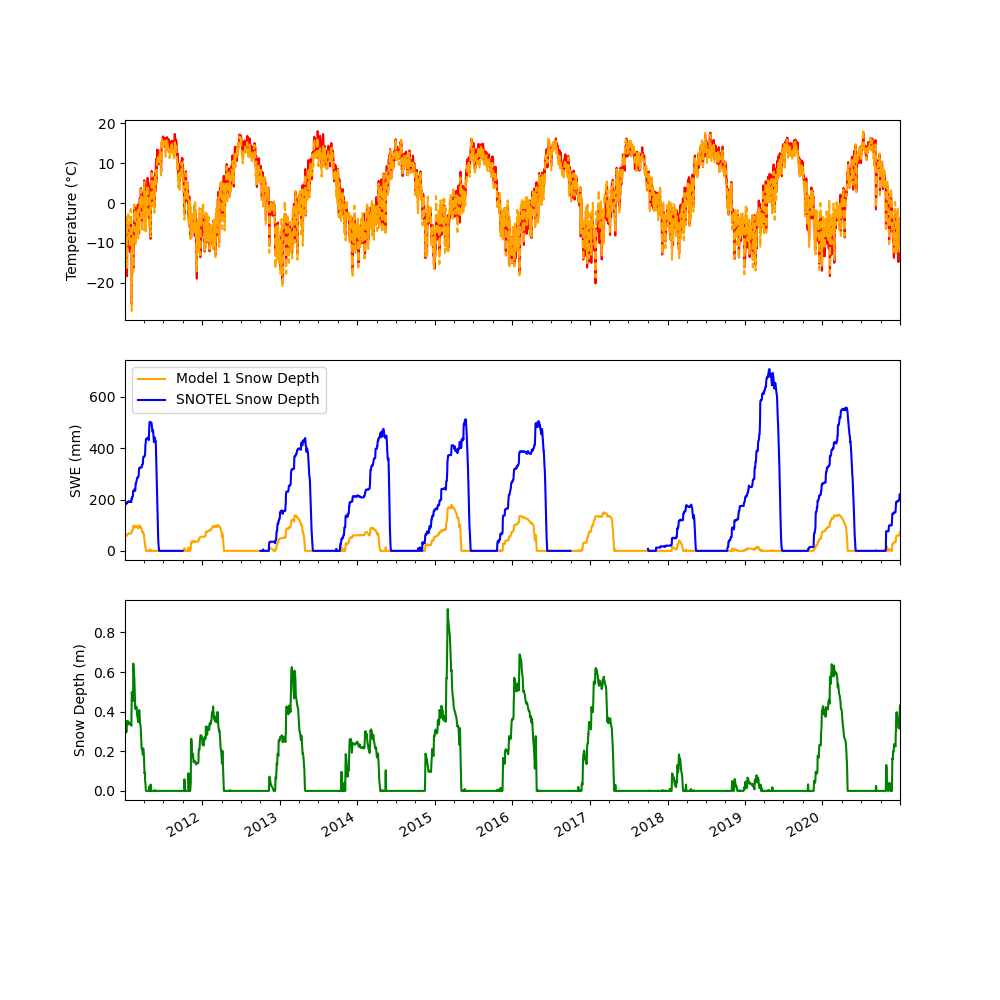

In [17]:
# Plot snow
fig, ax = plt.subplots(3, 1, figsize=(10, 10), sharex=True)
Tair_daily.plot(ax=ax[0], label='Tair (Daily Mean)', color='red')
Tair_daily2.plot(ax=ax[0], label='Tair2 (Daily Mean)', style='--', color='orange')
model_snow['snow'].plot(ax=ax[1], label='Model 1 Snow Depth', color='orange')
#model2_snow['snow'].plot(ax=ax[1], label='Model 2 Snow Depth', color='purple')
snotel_data.loc[start_date:end_date, 'swe_mm'].plot(ax=ax[1], label='SNOTEL Snow Depth', color='blue')
model_snow['snow_depth'].plot(ax=ax[2], label='Model Snow Depth (Depth)', color='green')
ax[0].set_ylabel('Temperature (°C)')
ax[1].set_ylabel('SWE (mm)')
ax[2].set_ylabel('Snow Depth (m)')
ax[1].legend()

### Bias and RMSE for snow depth and SWE


In [ ]:
# Combine daily snow datasets into a single frame for analysis
snow_data = pd.merge(
    model_snow['snow'],
    model2_snow['snow'],
    left_index=True, right_index=True, suffixes=('_model1', '_model2')
)

In [ ]:
snotel_swe = snotel_data.loc[start_date:end_date, 'swe_mm']
snotel_swe.index = snotel_swe.index + pd.Timedelta(hours=12)  # Adjust SNOTEL data to match model time
snow_data = pd.merge(
    snow_data,
    snotel_swe,
    left_index=True, right_index=True, suffixes=('', '_snotel')
)

In [ ]:
# Calculate bias and RMSE
snow_data.dropna(inplace=True)  # Ensure no NaN values in data
bias_model1 = (snow_data['snow_model1'] - snow_data['swe_mm']).mean()
bias_model2 = (snow_data['snow_model2'] - snow_data['swe_mm']).mean()
rmse_model1 = ((snow_data['snow_model1'] - snow_data['swe_mm']) ** 2).mean() ** 0.5
rmse_model2 = ((snow_data['snow_model2'] - snow_data['swe_mm']) ** 2).mean() ** 0.5

# Print bias and RMSE
print(f"Model 1 Bias: {bias_model1:.2f} mm, RMSE: {rmse_model1:.2f} mm")
print(f"Model 2 Bias: {bias_model2:.2f} mm, RMSE: {rmse_model2:.2f} mm")